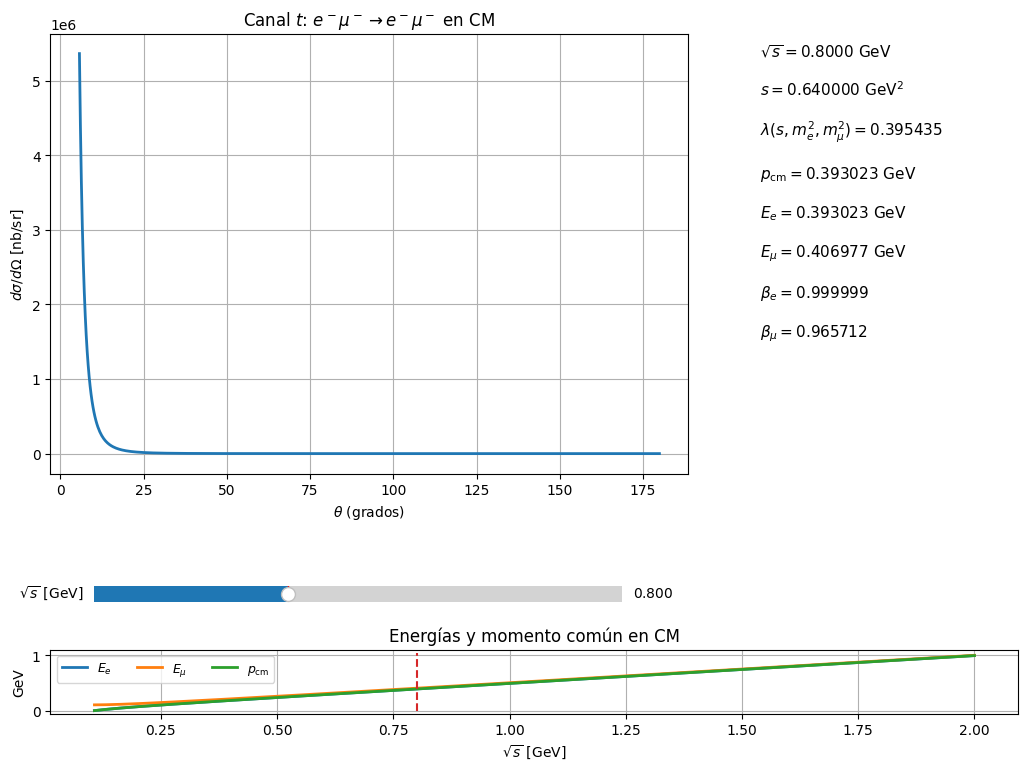

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

# ============================================================
#  e^- mu^- -> e^- mu^-  (canal t) en el sistema CM
#  Unidades: GeV, natural units
#  La sección eficaz diferencial se muestra en nb/sr
# ============================================================

alpha = 1 / 137.035999084
e4 = (4 * np.pi * alpha) ** 2

m_e = 0.00051099895   # GeV
m_mu = 0.1056583755   # GeV

# Conversión:
# 1 GeV^{-2} = 0.389379 mb = 3.89379e5 nb
GEV2_TO_NB = 3.89379e5

g = np.diag([1.0, -1.0, -1.0, -1.0])


def minkowski_dot(a, b):
    return a[0] * b[0] - np.dot(a[1:], b[1:])


def kallen(x, y, z):
    return x**2 + y**2 + z**2 - 2 * (x*y + x*z + y*z)


def contract_upper_upper(A, B):
    """
    Calcula A^{mu nu} B_{mu nu} a partir de A^{mu nu}, B^{alpha beta}
    usando la métrica de Minkowski.
    """
    return np.einsum('mn,ma,nb,ab->', A, g, g, B)


def cm_kinematics_em_scattering(s):
    """
    Cinemática exacta en CM para e mu -> e mu.
    """
    root_s = np.sqrt(s)
    lam = kallen(s, m_e**2, m_mu**2)
    if lam <= 0:
        raise ValueError("s está por debajo del umbral físico.")

    p = np.sqrt(lam) / (2 * root_s)
    E_e = (s + m_e**2 - m_mu**2) / (2 * root_s)
    E_mu = (s + m_mu**2 - m_e**2) / (2 * root_s)

    beta_e = p / E_e
    beta_mu = p / E_mu

    return {
        "sqrt_s": root_s,
        "s": s,
        "lambda": lam,
        "p": p,
        "E_e": E_e,
        "E_mu": E_mu,
        "beta_e": beta_e,
        "beta_mu": beta_mu,
    }


def dsigma_domega_t_channel(theta, s):
    """
    dσ/dΩ para e^- mu^- -> e^- mu^- en CM, calculada numéricamente
    a partir de tensores de traza.
    Resultado en GeV^{-2}.
    """
    kin = cm_kinematics_em_scattering(s)
    E_e = kin["E_e"]
    E_mu = kin["E_mu"]
    p = kin["p"]

    # Cuadrivectores en CM
    p1 = np.array([E_e, 0.0, 0.0, +p])
    p2 = np.array([E_mu, 0.0, 0.0, -p])
    p3 = np.array([E_e, p*np.sin(theta), 0.0, p*np.cos(theta)])
    p4 = np.array([E_mu, -p*np.sin(theta), 0.0, -p*np.cos(theta)])

    # t = (p1 - p3)^2
    q = p1 - p3
    t = minkowski_dot(q, q)

    # Tensor del electrón
    dot13 = minkowski_dot(p1, p3)
    A = 4.0 * (
        np.outer(p3, p1)
        + np.outer(p1, p3)
        - (dot13 - m_e**2) * g
    )

    # Tensor del muón
    dot24 = minkowski_dot(p2, p4)
    B = 4.0 * (
        np.outer(p4, p2)
        + np.outer(p2, p4)
        - (dot24 - m_mu**2) * g
    )

    Msq_bar = 0.25 * (e4 / t**2) * contract_upper_upper(A, B)

    # En dispersión elástica 2->2 en CM: |pf| = |pi| = p
    dsdo = (1.0 / (64.0 * np.pi**2 * s)) * Msq_bar
    return dsdo


# ------------------------------------------------------------
# Rango angular: evitamos θ=0 exacto por el pico hacia adelante
# ------------------------------------------------------------
theta = np.linspace(1e-1, np.pi - 1e-3, 600)
theta_deg = np.degrees(theta)

# Valor inicial de sqrt(s)
sqrt_s0 = 0.8  # GeV
s0 = sqrt_s0**2

# ------------------------------------------------------------
# Figura interactiva
# ------------------------------------------------------------
fig = plt.figure(figsize=(11, 8))
ax_curve = plt.axes([0.08, 0.35, 0.58, 0.55])
ax_text = plt.axes([0.72, 0.35, 0.24, 0.55])
ax_slider = plt.axes([0.12, 0.18, 0.48, 0.04])
ax_kin = plt.axes([0.08, 0.05, 0.88, 0.08])

ax_text.axis("off")

# Curva inicial
y0 = np.array([dsigma_domega_t_channel(t, s0) * GEV2_TO_NB for t in theta])
[line] = ax_curve.plot(theta_deg, y0, lw=2)
ax_curve.set_xlabel(r'$\theta$ (grados)')
ax_curve.set_ylabel(r'$d\sigma/d\Omega\ \mathrm{[nb/sr]}$')
ax_curve.set_title(r'Canal $t$: $e^-\mu^- \to e^-\mu^-$ en CM')
ax_curve.grid(True)

# Slider de sqrt(s)
slider = Slider(
    ax=ax_slider,
    label=r'$\sqrt{s}$ [GeV]',
    valmin=(m_e + m_mu) + 1e-3,
    valmax=2.0,
    valinit=sqrt_s0,
)

# Precomputo para panel cinemático
sqrt_s_vals = np.linspace((m_e + m_mu) + 1e-3, 2.0, 400)
lam_vals = np.array([kallen(x**2, m_e**2, m_mu**2) for x in sqrt_s_vals])
E_e_vals = np.array([(x**2 + m_e**2 - m_mu**2)/(2*x) for x in sqrt_s_vals])
E_mu_vals = np.array([(x**2 + m_mu**2 - m_e**2)/(2*x) for x in sqrt_s_vals])
p_vals = np.sqrt(np.maximum(lam_vals, 0.0)) / (2 * sqrt_s_vals)

ax_kin.plot(sqrt_s_vals, E_e_vals, label=r'$E_{e}$', lw=2)
ax_kin.plot(sqrt_s_vals, E_mu_vals, label=r'$E_{\mu}$', lw=2)
ax_kin.plot(sqrt_s_vals, p_vals, label=r'$p_{\rm cm}$', lw=2)
[vline] = ax_kin.plot([sqrt_s0, sqrt_s0], [0, max(E_mu_vals)*1.05], '--', lw=1.5)
ax_kin.set_xlabel(r'$\sqrt{s}$ [GeV]')
ax_kin.set_ylabel('GeV')
ax_kin.set_title('Energías y momento común en CM')
ax_kin.grid(True)
ax_kin.legend(loc='upper left', ncol=3, fontsize=9)


def update(val):
    sqrt_s = slider.val
    s = sqrt_s**2

    y = np.array([dsigma_domega_t_channel(t, s) * GEV2_TO_NB for t in theta])
    line.set_ydata(y)
    ax_curve.relim()
    ax_curve.autoscale_view()

    kin = cm_kinematics_em_scattering(s)

    text = (
        rf'$\sqrt{{s}} = {kin["sqrt_s"]:.4f}\ \mathrm{{GeV}}$' + '\n\n'
        rf'$s = {kin["s"]:.6f}\ \mathrm{{GeV}}^2$' + '\n\n'
        rf'$\lambda(s,m_e^2,m_\mu^2) = {kin["lambda"]:.6f}$' + '\n\n'
        rf'$p_{{\rm cm}} = {kin["p"]:.6f}\ \mathrm{{GeV}}$' + '\n\n'
        rf'$E_{{e}} = {kin["E_e"]:.6f}\ \mathrm{{GeV}}$' + '\n\n'
        rf'$E_{{\mu}} = {kin["E_mu"]:.6f}\ \mathrm{{GeV}}$' + '\n\n'
        rf'$\beta_{{e}} = {kin["beta_e"]:.6f}$' + '\n\n'
        rf'$\beta_{{\mu}} = {kin["beta_mu"]:.6f}$'
    )

    ax_text.clear()
    ax_text.axis("off")
    ax_text.text(0.02, 0.98, text, va='top', fontsize=11)

    vline.set_xdata([sqrt_s, sqrt_s])

    fig.canvas.draw_idle()


slider.on_changed(update)
update(sqrt_s0)

plt.show()